In [77]:
#!pip install -U torchao
#!pip install -U peft transformers accelerate

In [2]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [78]:
#!pip install -U transformers peft accelerate
import importlib.util

print(importlib.util.find_spec("torchao"))

None


In [5]:
import torch
import torch.nn as nn
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-0.5B"
device = "cuda"

# ============================================================
# 1. Load model WITHOUT PEFT (important fix)
# ============================================================

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16
).to(device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# freeze base model
for p in model.parameters():
    p.requires_grad = False


# ============================================================
# 2. TinyLoRA layer (CORRECT: inside forward pass)
# ============================================================

class TinyLinear(nn.Module):

    def __init__(self, base_layer, latent_dim=13, rank=4):
        super().__init__()

        self.base = base_layer

        in_dim = base_layer.in_features
        out_dim = base_layer.out_features

        self.latent = nn.Parameter(torch.randn(latent_dim))

        self.A = nn.Linear(latent_dim, rank * in_dim)
        self.B = nn.Linear(latent_dim, out_dim * rank)

        self.rank = rank
        self.in_dim = in_dim
        self.out_dim = out_dim

    def forward(self, x):

        A = self.A(self.latent).view(self.rank, self.in_dim)
        B = self.B(self.latent).view(self.out_dim, self.rank)

        delta_W = B @ A  # (out, in)

        W = self.base.weight + delta_W.to(self.base.weight.dtype)

        return torch.nn.functional.linear(x, W, self.base.bias)


# ============================================================
# 3. Replace ONE attention projection
# ============================================================

model.model.layers[0].self_attn.q_proj = TinyLinear(
    model.model.layers[0].self_attn.q_proj
).to(device)


# ============================================================
# 4. Optimizer (NOW WORKS)
# ============================================================

optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-3
)


# ============================================================
# 5. Data
# ============================================================

examples = [
    ("Convert to pirate speech: Hello my friend", "Ahoy matey!"),
    ("Convert to pirate speech: Where are you going?", "Where be ye going?"),
]


# ============================================================
# 6. TRAINING LOOP (NOW GRADIENTS FLOW)
# ============================================================

model.train()

for epoch in range(30):

    total_loss = 0

    for inp, out in examples:

        text = inp + out

        tokens = tokenizer(text, return_tensors="pt").to(device)

        outputs = model(**tokens, labels=tokens["input_ids"])

        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(epoch, total_loss)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

0 12.220807552337646
1 11.109045505523682
2 10.660959243774414
3 10.614744186401367
4 10.863808631896973
5 11.145841121673584
6 11.57094144821167
7 11.56830883026123
8 11.610554695129395
9 11.632374286651611
10 11.547886371612549
11 11.432661056518555
12 11.350150108337402
13 11.473444938659668
14 11.285122871398926
15 11.25661325454712
16 11.217984676361084
17 11.191667556762695
18 11.173916816711426
19 11.134905338287354
20 11.119569301605225
21 11.103658676147461
22 11.053117275238037
23 11.128113269805908
24 11.112195014953613
25 11.079044818878174
26 11.044224262237549
27 11.031444072723389
28 11.00764513015747
29 10.996132850646973



=== TinyLoRA dim=2 ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

step 0: 11.5923
step 1: 11.1214
step 2: 10.8217
step 3: 10.5356
step 4: 10.2628
step 5: 9.9702
step 6: 9.6691
step 7: 9.3685
step 8: 9.0594
step 9: 8.7164
step 10: 8.3777
step 11: 8.0028
step 12: 7.6303
step 13: 7.2473
step 14: 6.8783

=== TinyLoRA dim=4 ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

step 0: 12.3339
step 1: 11.8797
step 2: 11.5255
step 3: 11.2327
step 4: 10.9533
step 5: 10.6831
step 6: 10.4222
step 7: 10.1773
step 8: 9.9314
step 9: 9.6897
step 10: 9.4518
step 11: 9.2082
step 12: 8.9759
step 13: 8.7458
step 14: 8.5284

=== TinyLoRA dim=8 ===


...

step 0: 11.7784
step 1: 11.5425
step 2: 11.3473
step 3: 11.1448
step 4: 10.9611
step 5: 10.7679
step 6: 10.5568
step 7: 10.3419
step 8: 10.0911
step 9: 9.8437
step 10: 9.5679
step 11: 9.2815
step 12: 8.9830
step 13: 8.6764
step 14: 8.3677

=== TinyLoRA dim=32 ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

step 0: 11.8837
step 1: 11.6613
step 2: 11.4754
step 3: 11.2856
step 4: 11.0838
step 5: 10.8772
step 6: 10.6176
step 7: 10.3231
step 8: 9.9911
step 9: 9.6033
step 10: 9.1897
step 11: 8.7466
step 12: 8.2932
step 13: 7.8246
step 14: 7.3322

=== TinyLoRA dim=64 ===


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

step 0: 11.8760
step 1: 11.6535
step 2: 11.4427
step 3: 11.2160
step 4: 10.9411
step 5: 10.5886
step 6: 10.1665
step 7: 9.6703
step 8: 9.1223
step 9: 8.5485
step 10: 7.9477
step 11: 7.3293
step 12: 6.6444
step 13: 5.9316
step 14: 5.2186


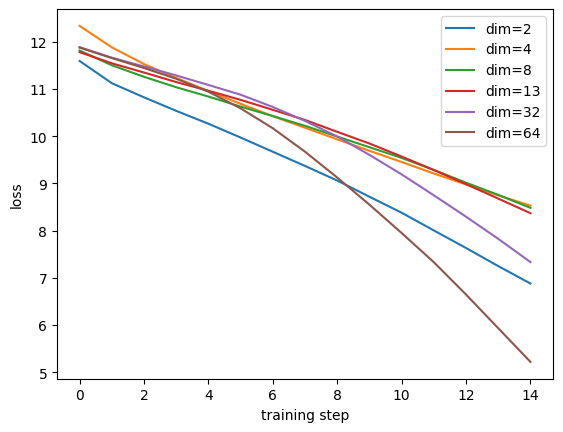

In [76]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

# ============================================================
# 0. DEVICE
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_ID = "Qwen/Qwen2.5-0.5B"


# ============================================================
# 1. TASKS
# ============================================================
TASKS = [
    {
        "name": "pirate",
        "data": [
            ("Convert to pirate speech: Hello my friend", "Ahoy matey!"),
            ("Convert to pirate speech: I am happy", "I be happy"),
        ]
    },
    {
        "name": "formal",
        "data": [
            ("Make formal: hey what’s up", "Greetings, how are you?"),
            ("Make formal: can you help me", "Could you assist me?")
        ]
    },
    {
        "name": "style_short",
        "data": [
            ("Shorten: artificial intelligence is transforming the world",
             "AI is transforming the world"),
        ]
    }
]


# ============================================================
# 2. TinyLoRA LAYER (FIXED + STABLE)
# ============================================================
class TinyLoRALayer(nn.Module):

    def __init__(self, base_layer, latent_dim=13, rank=4):
        super().__init__()

        self.base = base_layer.to(device)

        self.in_features = base_layer.in_features
        self.out_features = base_layer.out_features

        self.rank = rank
        self.in_dim = self.in_features
        self.out_dim = self.out_features

        # latent in fp32 for stability
        self.latent = nn.Parameter(torch.randn(latent_dim) * 0.02)

        self.A = nn.Linear(latent_dim, rank * self.in_dim)
        self.B = nn.Linear(latent_dim, self.out_dim * rank)

    def forward(self, x):

        device = x.device

        latent = self.latent.to(device, dtype=torch.float32)

        A = self.A(latent).view(self.rank, self.in_dim)
        B = self.B(latent).view(self.out_dim, self.rank)

        # full-rank update in fp32
        delta_W = B @ A

        W_base = self.base.weight.to(device=device, dtype=torch.float32)

        scale = 0.01
        W = W_base + scale * delta_W

        # match inference dtype
        W = W.to(dtype=x.dtype).contiguous()

        bias = None
        if self.base.bias is not None:
            bias = self.base.bias.to(device=device, dtype=x.dtype)

        return F.linear(x, W, bias)


# ============================================================
# 3. MODEL LOADING
# ============================================================
def fresh_model():

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16
    ).to(device)

    for p in model.parameters():
        p.requires_grad = False

    return model


# ============================================================
# 4. INJECT TINYLORA
# ============================================================
def inject_tinylora(model, latent_dim, rank):

    for layer in model.model.layers:

        layer.self_attn.q_proj = TinyLoRALayer(
            layer.self_attn.q_proj,
            latent_dim=latent_dim,
            rank=rank
        )

        layer.self_attn.v_proj = TinyLoRALayer(
            layer.self_attn.v_proj,
            latent_dim=latent_dim,
            rank=rank
        )

    return model.to(device)


# ============================================================
# 5. TRAINING LOOP (FIXED)
# ============================================================
def train_model(model, tokenizer, data, steps=10):

    model.train()

    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=1e-3
    )

    losses = []

    for step in range(steps):

        step_loss = 0.0

        for inp, out in data:

            text = inp + out

            tokens = tokenizer(text, return_tensors="pt")
            tokens = {k: v.to(device) for k, v in tokens.items()}

            outputs = model(**tokens, labels=tokens["input_ids"])
            loss = outputs.loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            step_loss += loss.item()

        losses.append(step_loss)
        print(f"step {step}: {step_loss:.4f}")

    return losses


# ============================================================
# 6. EVALUATION
# ============================================================
def evaluate(model, tokenizer, prompt):

    model.eval()

    tokens = tokenizer(prompt, return_tensors="pt")
    tokens = {k: v.to(device) for k, v in tokens.items()}

    with torch.no_grad():
        out = model.generate(**tokens, max_new_tokens=30)

    return tokenizer.decode(out[0], skip_special_tokens=True)


# ============================================================
# 7. EXPERIMENT RUNNER
# ============================================================
def run_tinylora_experiment(tokenizer):

    results = {}
    latent_dims = [2, 4, 8, 13, 32, 64]

    for d in latent_dims:

        print(f"\n=== TinyLoRA dim={d} ===")

        model = fresh_model()
        model = inject_tinylora(model, latent_dim=d, rank=4)

        losses = train_model(
            model,
            tokenizer,
            TASKS[0]["data"],
            steps=15
        )

        results[d] = losses

    return results


# ============================================================
# 8. PLOTTING
# ============================================================
def plot_results(results):

    plt.figure()

    for dim, losses in results.items():
        plt.plot(losses, label=f"dim={dim}")

    plt.xlabel("training step")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


# ============================================================
# 9. MAIN
# ============================================================
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

results = run_tinylora_experiment(tokenizer)

plot_results(results)